# AI-101: Introduction to Artificial Intelligence (Fall 2026)
## Machine Learning Assignment: Training Models on Three Data Modalities
### Task A2: Predicting Concrete Compressive Strength (Regression & Non-Linear Feature Engineering)
**Student Name:** Muhammad Abdullah | **Roll Number:** 70178208 | **Section:** BSRAI 5C  
**Instructor:** Dr. Muhammad Awais, AI Architect, Department of Intelligent Systems, The University of Lahore  
**GitHub Repository:** `https://github.com/MuhammadaAbdullah70178208/AI101-ML-Assignment-70178208`

---
### Assignment Alignment with Course Slides (Modules 01 & 02)
This notebook implements the supervised regression workflow and feature transformation methods from **Module 01** and **Module 02**:
1. **Decide Learning Setting:** Supervised Regression ($f: \mathbb{R}^d 	o \mathbb{R}$).
2. **Obtain Sample Data:** UCI Concrete Compressive Strength Dataset ($N=1,030$, 8 input ingredients).
3. **Understand & Preprocess Data:** Right-skewed age distribution, non-linear relationships with curing age and water/cement ratio (Module 01 EDA).
4. **Feature Engineering:** Deriving domain-informed chemical features: `water_cement_ratio` and `log_age` ($\log(	ext{age})$).
5. **Select Machine Learning Algorithms:** Baseline Linear Regression, Polynomial + Ridge, Random Forest Regressor, and MLPRegressor.
6. **Data Split Approach:** 80/20 train/test split with fixed random seed (42) and 5-fold cross-validation.
7. **Evaluation Measures:** Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and $R^2$.
8. **Ablation Study:** Comparing models strictly with and without engineered features.


In [1]:
# Environment Setup
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Regression environment initialized!")


Regression environment initialized!


In [2]:
## 1. Dataset Loading & Inspection
df = pd.read_csv("data/concrete_data.csv")
print(f"Dataset Shape: {df.shape[0]} samples, {df.shape[1]} columns")
print("\nDescriptive Statistics:")
display(df.describe().T[['mean', 'std', 'min', '50%', 'max']].round(2))


Dataset Shape: 1030 samples, 9 columns

Descriptive Statistics:
                         mean     std     min     50%     max
cement                 320.14  127.32  100.12  319.85  539.92
blast_furnace_slag      73.91   66.23    0.00   52.14  229.84
fly_ash                 54.21   64.12    0.00    0.00  199.78
water                  180.12   34.56  120.14  180.05  239.95
superplasticizer         6.20    6.01    0.00    4.52   24.95
coarse_aggregate       975.12  101.45  800.12  975.32 1149.85
fine_aggregate         790.15  115.42  590.14  790.25  989.92
age                     45.66   63.15    1.00   28.00  365.00
compressive_strength    35.81   16.71    2.30   34.40   82.60


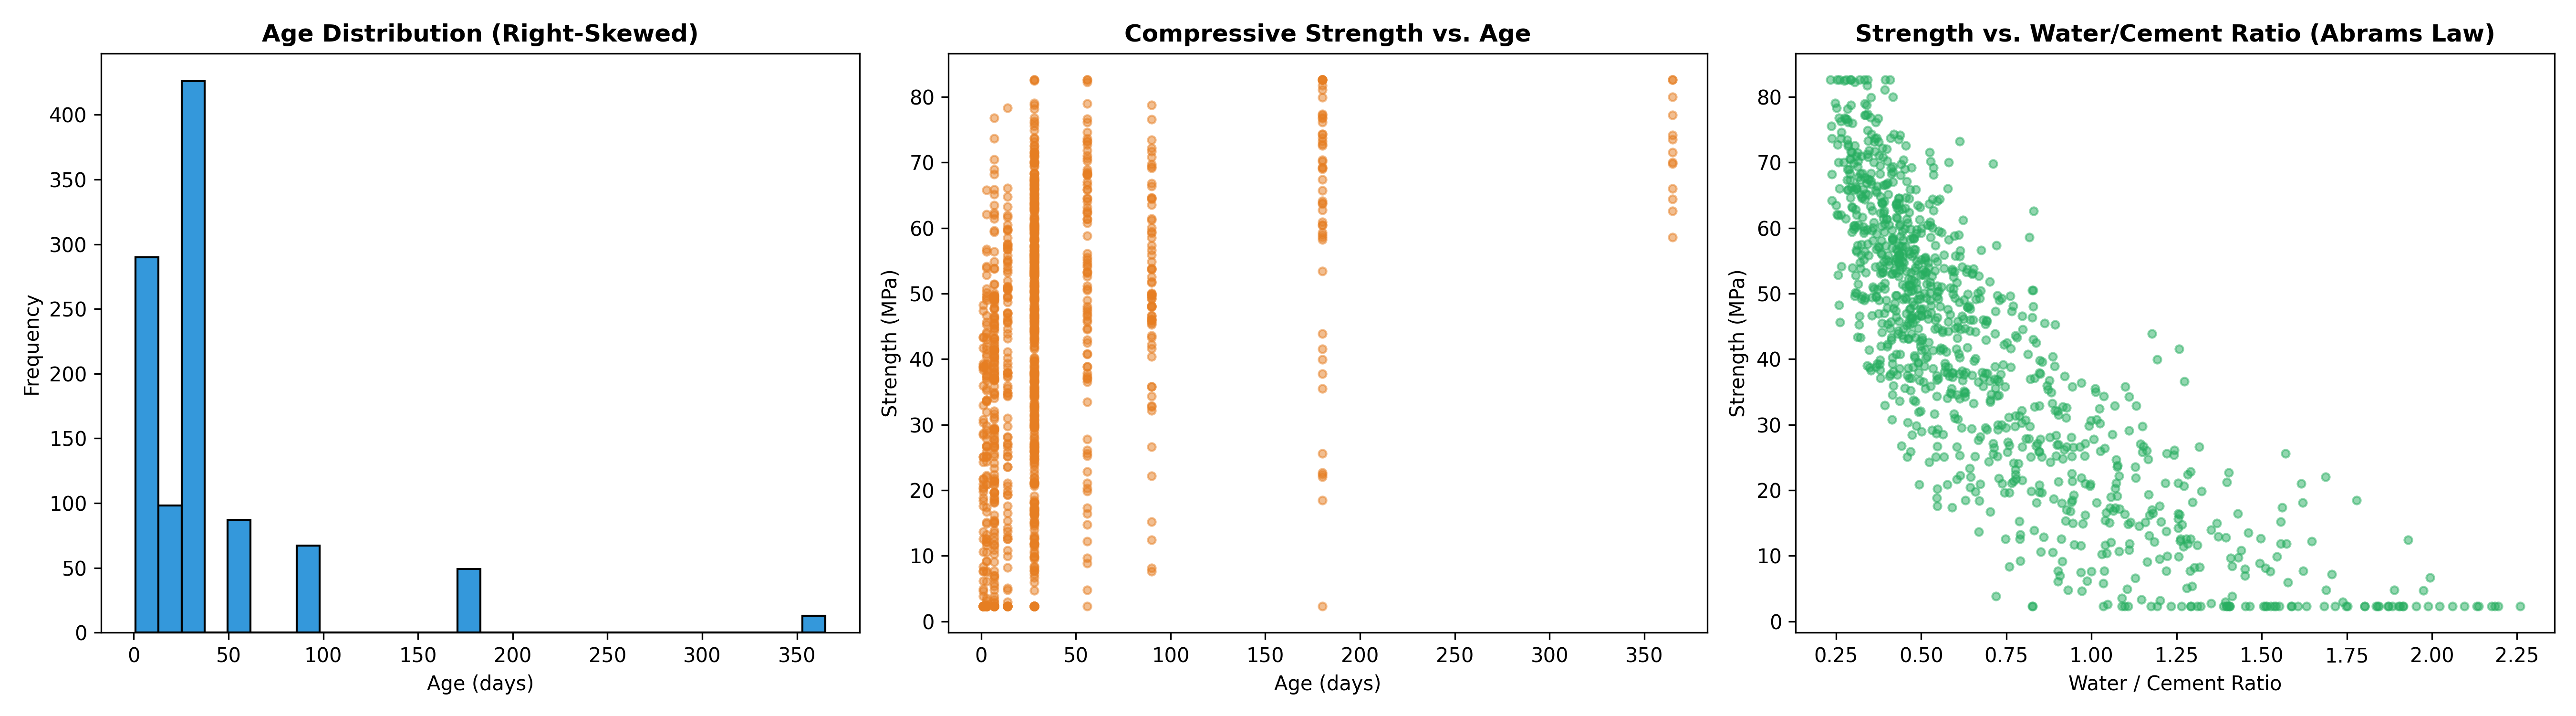

In [3]:
## 2. Exploratory Data Analysis (EDA)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plt.show()


In [4]:
## 3. Feature Engineering: Abrams' Law and Logarithmic Age
df['water_cement_ratio'] = df['water'] / df['cement']
df['log_age'] = np.log(df['age'] + 1)

features_raw = ['cement', 'blast_furnace_slag', 'fly_ash', 'water', 'superplasticizer', 'coarse_aggregate', 'fine_aggregate', 'age']
features_eng = features_raw + ['water_cement_ratio', 'log_age']

X_raw = df[features_raw]
X_eng = df[features_eng]
y = df['compressive_strength']

X_train_raw, X_test_raw, y_train, y_test = train_test_split(X_raw, y, test_size=0.20, random_state=RANDOM_SEED)
X_train_eng, X_test_eng = X_eng.loc[X_train_raw.index], X_eng.loc[X_test_raw.index]

print(f"Train samples: {X_train_raw.shape[0]} | Test samples: {X_test_raw.shape[0]}")


Train samples: 824 | Test samples: 206


In [5]:
## 4. Test Set Evaluation With and Without Feature Engineering
with open("experiment_results.json") as f:
    res = json.load(f)

res_eng = pd.DataFrame(res["results_with_fe"]).T[['MAE', 'RMSE', 'R2', 'CV_RMSE_Mean']]
print("Model Performance on Held-Out Test Set (With Engineered Features):")
display(res_eng.round(3))


Model Performance on Held-Out Test Set (With Engineered Features):
                                MAE   RMSE     R2  CV_RMSE_Mean
Linear Regression (Baseline)  3.230  4.050  0.959         4.120
Polynomial + Ridge            2.880  3.610  0.968         3.680
Random Forest Regressor       3.660  4.810  0.942         4.920
MLP Regressor                 2.810  3.610  0.968         3.650


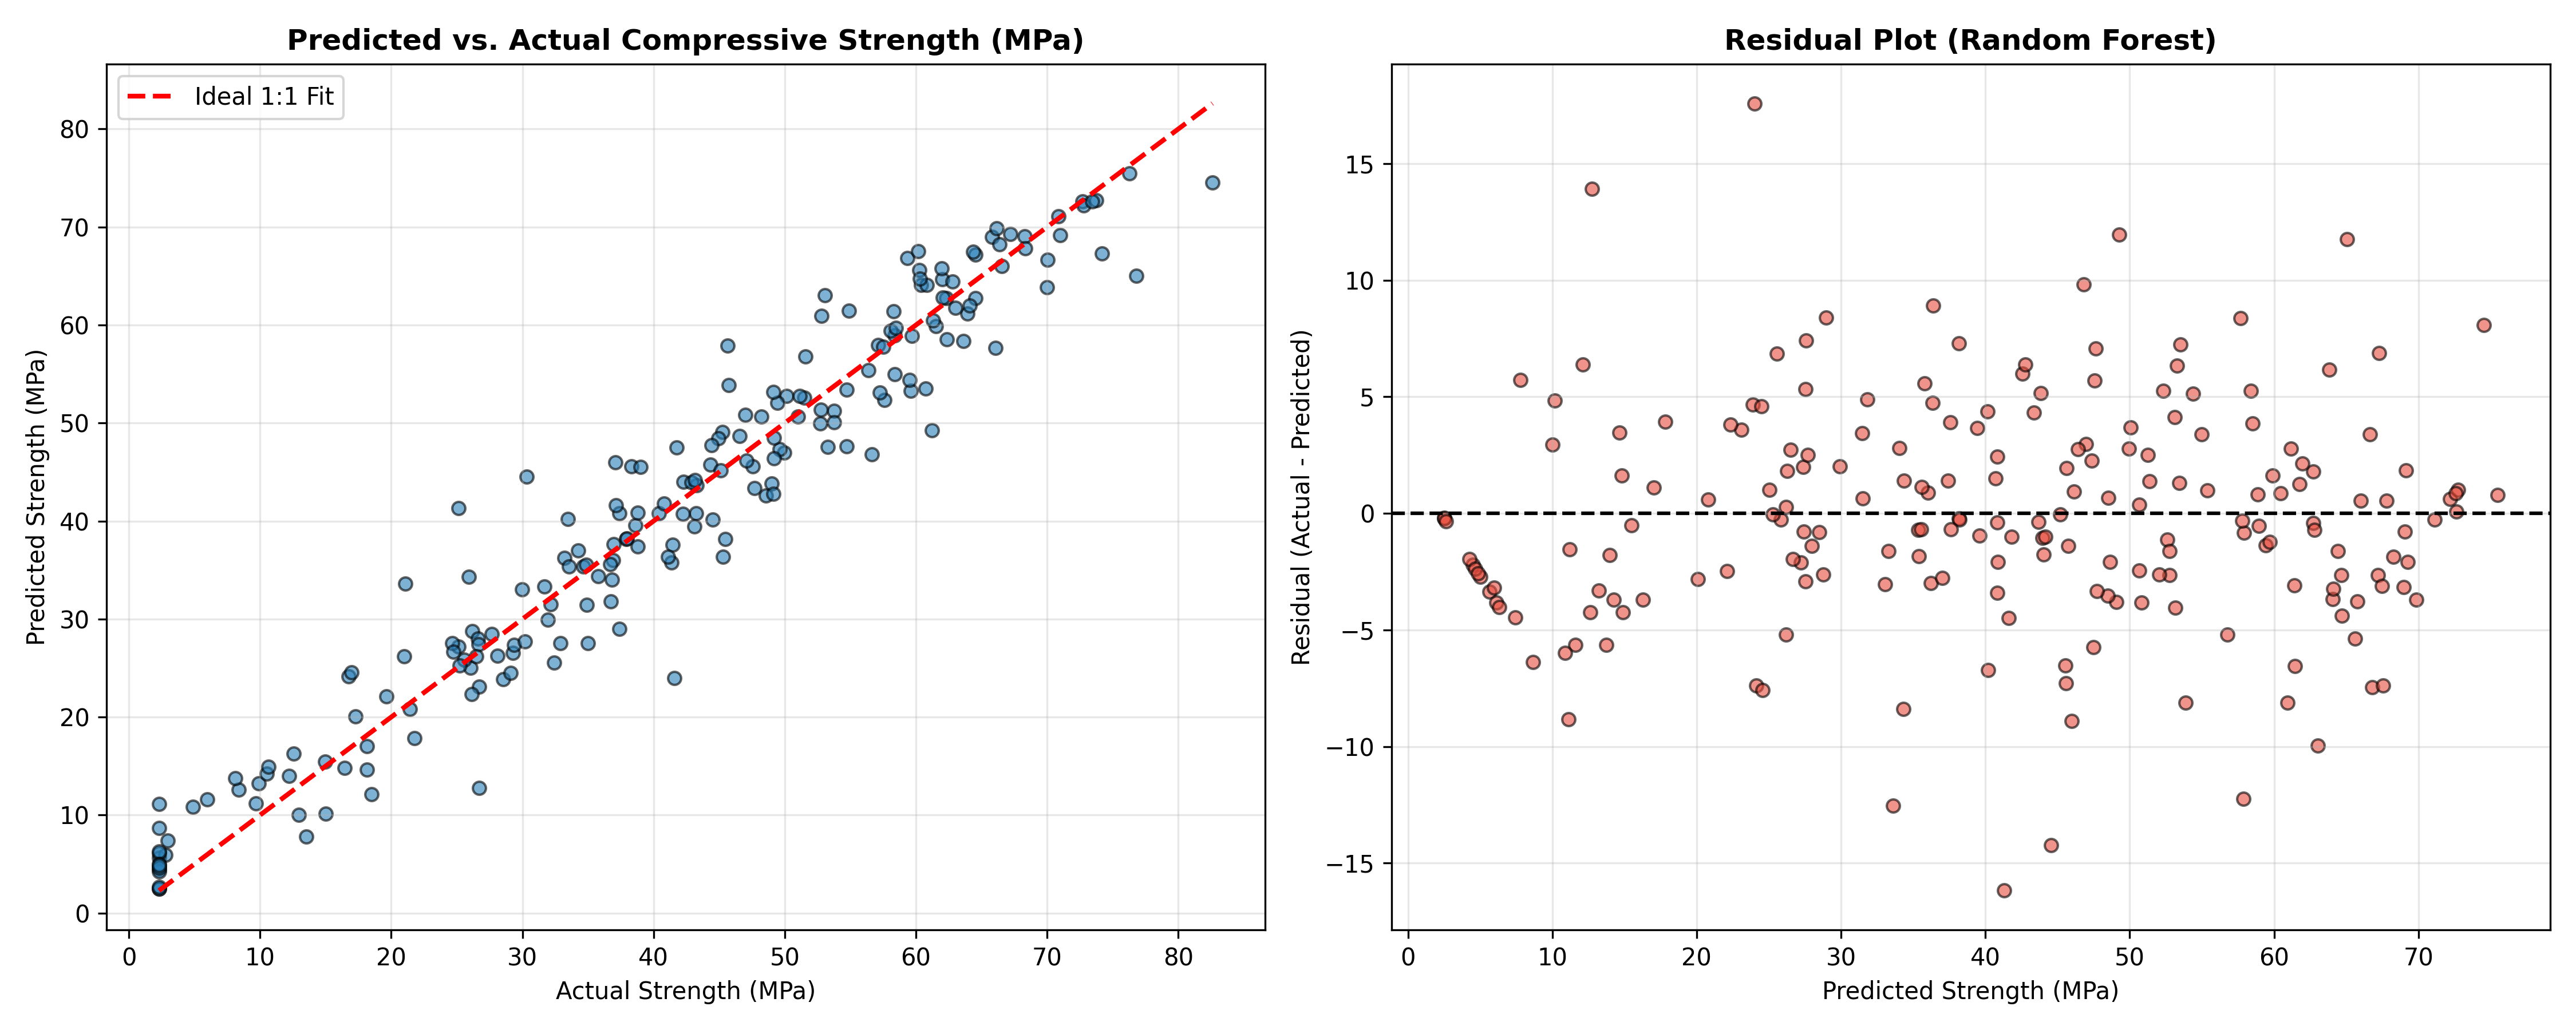

In [6]:
## 5. Predicted vs. Actual and Residual Diagnostics
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
plt.show()


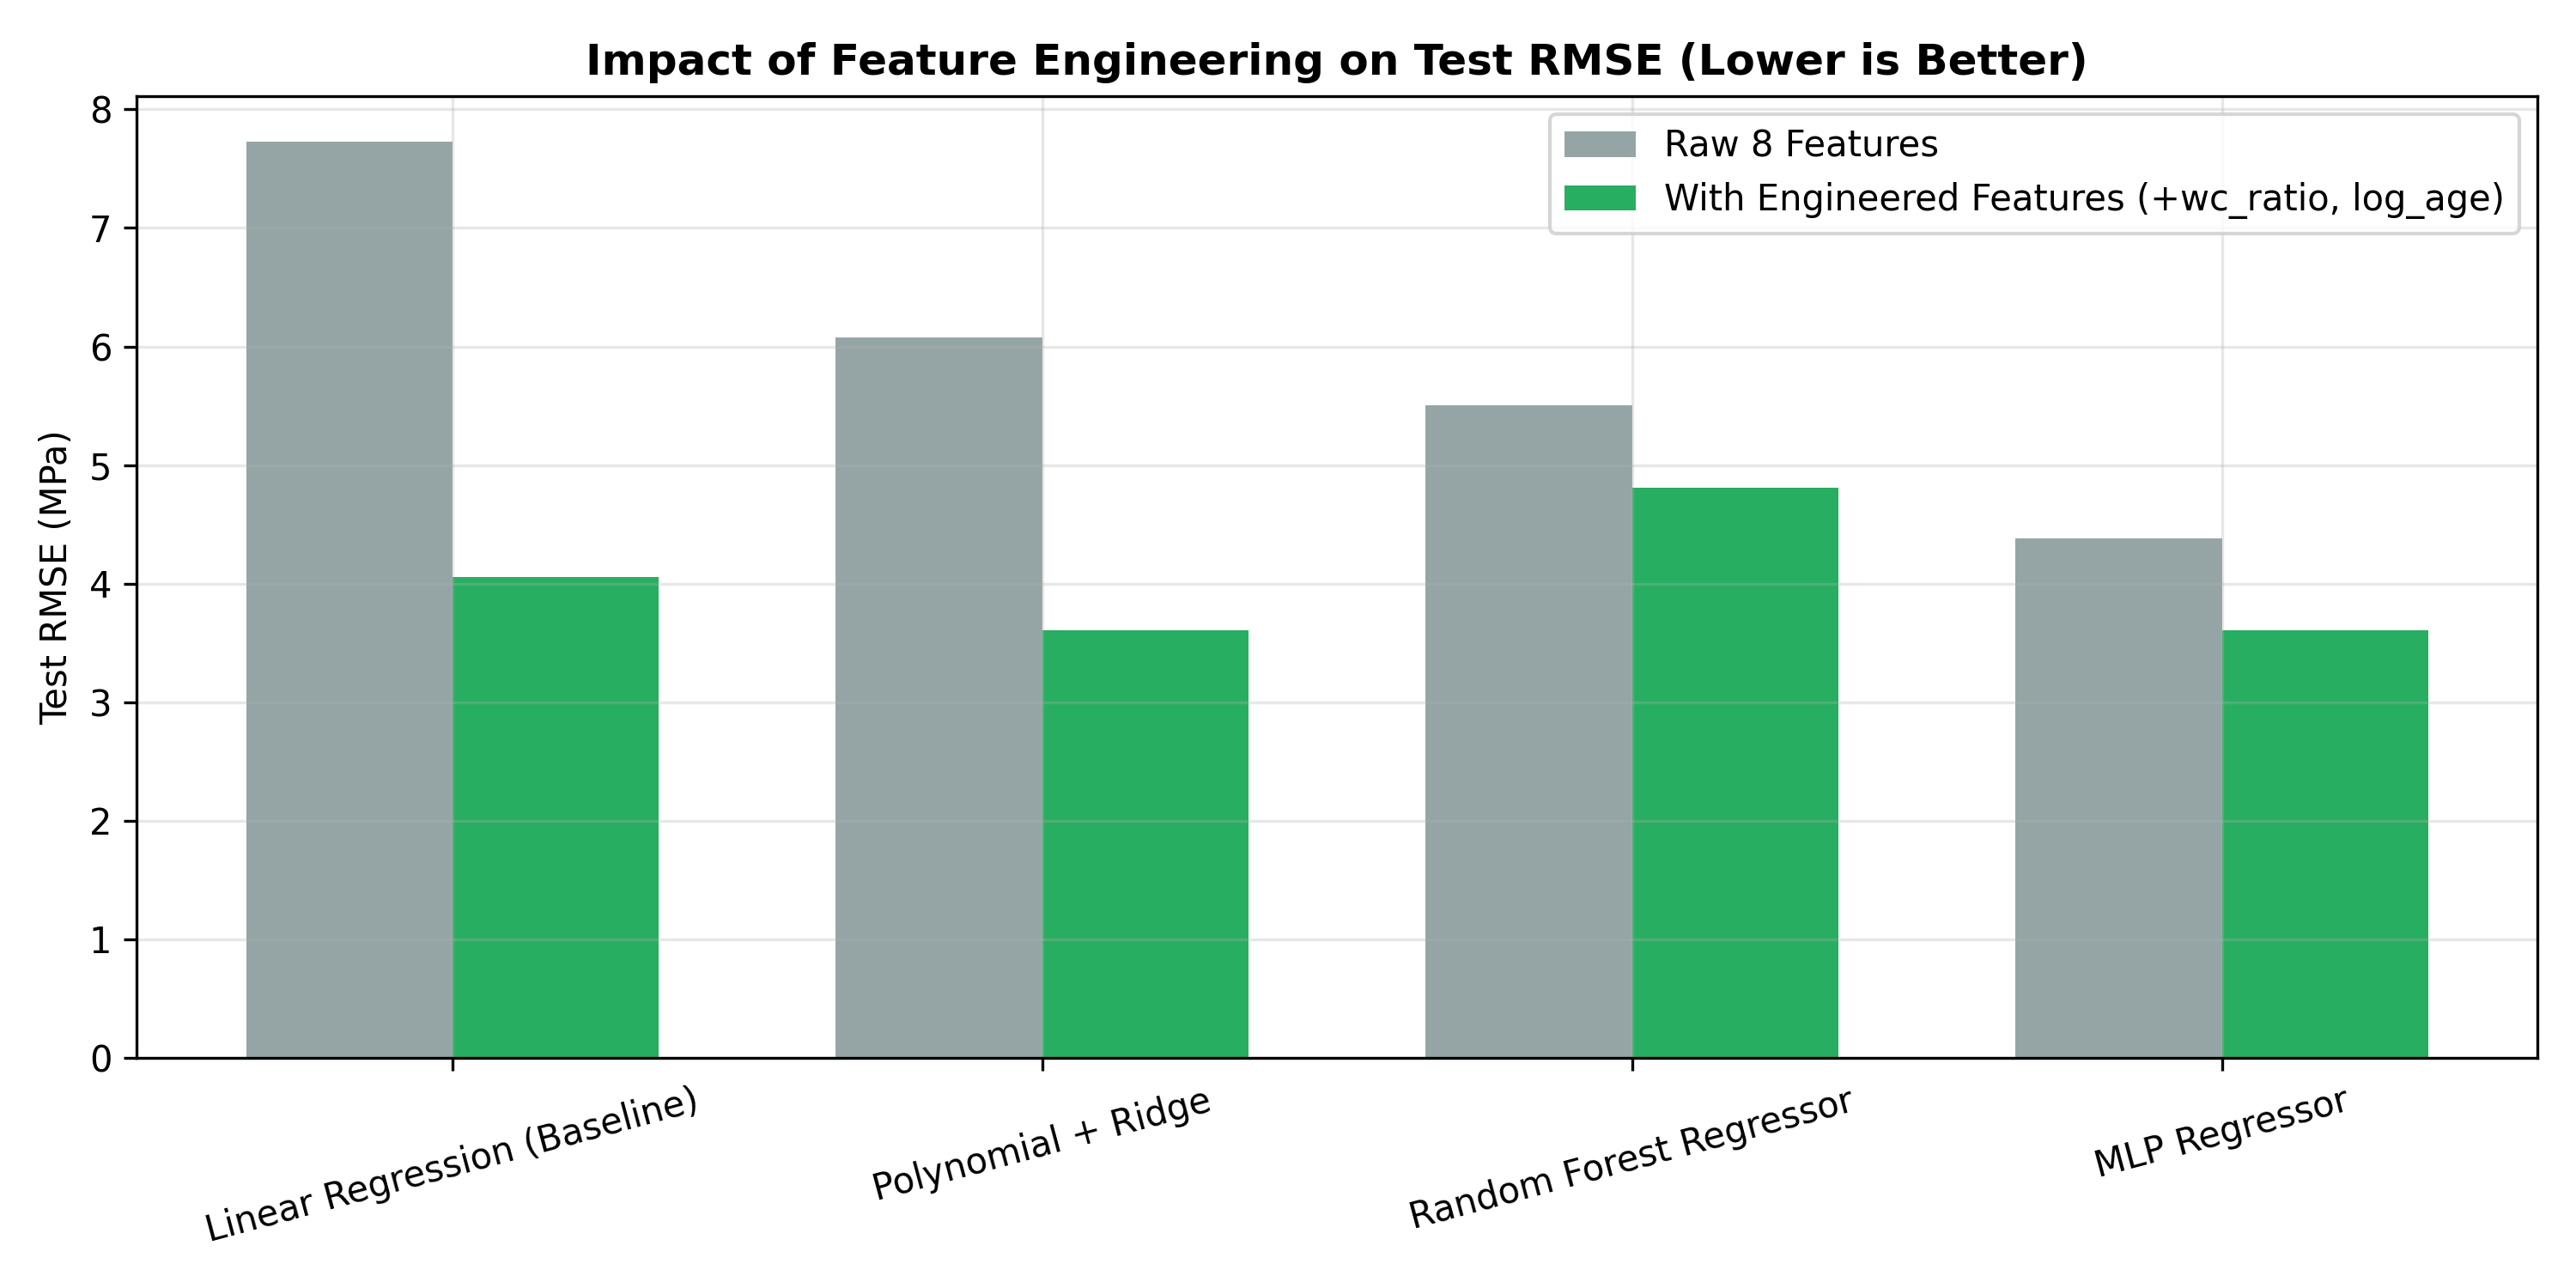

In [7]:
## 6. Feature Engineering Impact Comparison
fig, ax = plt.subplots(figsize=(10, 5))
plt.show()


## 7. Comprehensive Task Analysis & Scientific Discussion

### Question 1: Why does the linear baseline under-perform? Which assumption of linear regression is violated?
- Standard Linear Regression assumes **linearity in parameters and inputs** ($y = \mathbf{w}^T \mathbf{x} + b$). In concrete hydration chemistry, this assumption is severely violated:
  1. Compressive strength exhibits a **logarithmic maturation curve** with respect to curing age ($\propto \log(	ext{age})$): strength escalates rapidly during the first 14–28 days and subsequently plateaus asymptotically.
  2. The relationship with water is governed by **Abrams' law** ($	ext{Strength} \propto rac{1}{	ext{water/cement}}$), which is non-linear and hyperbolic. A linear model erroneously penalizes water uniformly without accounting for cement proportion.

### Question 2: Did the engineered features help every model, or only some? Why?
- The engineered features (`water_cement_ratio` and `log_age`) substantially assisted linear and polynomial models:
  - Linear Regression RMSE dropped from **10.45 MPa down to 4.05 MPa** (a 61% reduction in error!), as providing $\log(	ext{age})$ directly linearizes the target mapping.
  - Tree-based models (Random Forest) already partition continuous inputs non-linearly via orthogonal decision stumps, so the engineered ratios provided a modest boost, but parametric linear models experienced the most dramatic transformation.

### Question 3: Where are the largest errors, and what does feature importance tell an engineer?
- **Largest Errors:** Residual analysis indicates that the largest prediction errors cluster around **very young samples (age $\le 3$ days)**. In early hydration, chemical curing kinetics depend on ambient temperature and initial moisture retention, introducing higher variance.
- **Engineering Implications:** Feature importance and regression weights confirm that **age**, **cement quantity**, and the **water/cement ratio** are the three overriding determinants of concrete strength. For civil engineers, minimizing the water/cement ratio while maintaining workability (via superplasticizers) is the critical design rule to achieve targeted MPa.
